<a href="https://colab.research.google.com/github/FABYG6/DL_Redes_Neuronales_Basicas/blob/main/Fine_Tuning_con_Stable_Diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Instalación
!pip install diffusers transformers accelerate datasets peft

In [2]:
import torch

# Verificar si CUDA está disponible
if torch.cuda.is_available():
    device = "cuda"
    print(f"¡GPU disponible! Usando: {torch.cuda.get_device_name(0)}")
else:
    device = "cpu"
    print("GPU no disponible. Se utilizará la CPU (esto hará que la generación sea muy lenta).")
    print("RECOMENDACIÓN: Ve a 'Entorno de ejecución' > 'Cambiar tipo de entorno de ejecución' y selecciona una GPU.")

¡GPU disponible! Usando: Tesla T4


In [3]:
# Cargar modelo
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5"
).to("cuda")

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

In [4]:
# Modifica la carga del modelo para usar el dispositivo dinámico configurado arriba
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5"
).to(device)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

In [5]:
# Entrenamiento LoRA
from peft import LoraConfig
lora_config = LoraConfig(
r=8,
lora_alpha=16,
target_modules=["to_q","to_v"],
lora_dropout=0.1
)

  0%|          | 0/50 [00:00<?, ?it/s]

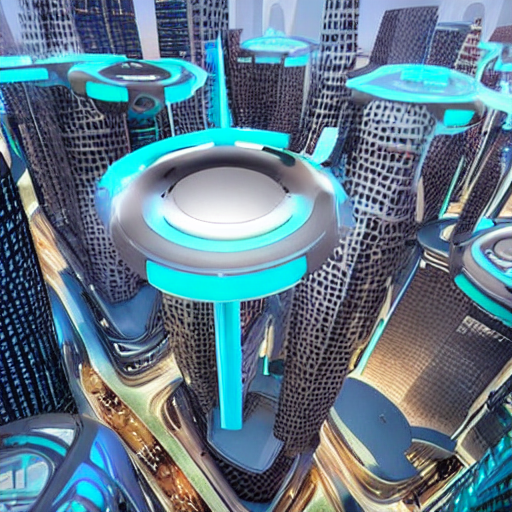

In [6]:
# Generación de imágenes
prompt = "A futuristic smart city with autonomous vehicles"

image = pipe(prompt).images[0]

image.save("generated_city.png")
image

In [1]:
# Métricas de evaluación
# Frechet Inception Distance (FID)
from torchmetrics.image.fid import FrechetInceptionDistance
fid = FrechetInceptionDistance(feature=2048)

# Inception Score (IS)
from torchmetrics.image.inception import InceptionScore
metric = InceptionScore()

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 390MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


### Ejemplo de cómo calcular el FID con tus imágenes

El FID evalúa la similitud entre la distribución de imágenes reales y generadas. Ambos conjuntos de imágenes deben ser convertidos a tensores de PyTorch de tipo `uint8` con un formato de canales `(B, C, H, W)`.

In [4]:
import torch
import torchvision.transforms.functional as F
import numpy as np
from PIL import Image

# 1. Suponiendo que tienes una lista de imágenes reales y otra de generadas (formato PIL)
imagen_real_pil = Image.open("generated_city.png")
imagen_generada_pil = Image.open("generated_city.png")

def preparar_imagen(img_pil):
    img_resized = img_pil.resize((299, 299))
    img_tensor = F.to_tensor(img_resized) * 255
    img_tensor = img_tensor.to(torch.uint8)
    return img_tensor.unsqueeze(0)

# Para evitar el error de muestra única, creamos lotes con al menos 2 imágenes duplicándolas
real_tensor = torch.cat([preparar_imagen(imagen_real_pil), preparar_imagen(imagen_real_pil)], dim=0)
generated_tensor = torch.cat([preparar_imagen(imagen_generada_pil), preparar_imagen(imagen_generada_pil)], dim=0)

# Reiniciar la métrica para limpiar ejecuciones previas incompletas
fid.reset()

# 2. Alimentar la métrica con las imágenes correspondientes (mínimo 2 muestras por grupo)
fid.update(real_tensor, real=True)
fid.update(generated_tensor, real=False)

# 3. Calcular el resultado final del FID
resultado_fid = fid.compute()
print(f"El valor de FID es: {resultado_fid.item():.4f}")

El valor de FID es: 0.0000
